In [13]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

#load dataset
data=load_breast_cancer()
X=data.data
y=data.target
print("Dataset shape:",X.shape)
print("Target shape:",y.shape)

print("Feature names :")
print(data.feature_names)
print("Class names:")
print(data.target_names)

#display the dataset
df=pd.DataFrame(X,columns=data.feature_names)
df['Target']=y
print(df.head())

#separate input and output variables
X=df.drop('Target',axis=1)
y=df['Target']
print("Input Shape:",X.shape)
print("Output Shape:",y.shape)





Dataset shape: (569, 30)
Target shape: (569,)
Feature names :
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Class names:
['malignant' 'benign']
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.5

In [14]:
#split the dataset
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Traning Data:",X_train.shape)
print("Testing Data:",X_test.shape)

#standardize
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
print("Traning shape:",X_train_scaled.shape)
print("Testing shape:",X_test_scaled.shape)

Traning Data: (455, 30)
Testing Data: (114, 30)
Traning shape: (455, 30)
Testing shape: (114, 30)


In [15]:
#create and train a linear svm classifier
linear_svm=SVC(kernel='linear',C=1.0)
linear_svm.fit(X_train_scaled,y_train)

#predict using the linear svm
y_pred_linear=linear_svm.predict(X_test_scaled)
print("Predicted values:",y_pred_linear)
print("Actual values:",y_test.values)


Predicted values: [0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]
Actual values: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [18]:
#evaluate linear svm
accuracy_linear=accuracy_score(y_test,y_pred_linear)
print('Linear SVM Accuracy:',accuracy_linear)
cm_linear=confusion_matrix(y_test,y_pred_linear)
print("Confusion Matrix:")
print(cm_linear)
print(classification_report(
    y_test,y_pred_linear,target_names=data.target_names
))


Linear SVM Accuracy: 0.9736842105263158
Confusion Matrix:
[[41  1]
 [ 2 70]]
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [19]:
#create and train an RBF Krenal SVM
rdf_svm=SVC(kernel='rbf',C=1.0)
rdf_svm.fit(X_train_scaled,y_train)
#predict using rbf
y_pred_rbf=rdf_svm.predict(X_test_scaled)
print("Predicted values:",y_pred_rbf)
print("Actual values:",y_test.values)

Predicted values: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]
Actual values: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [22]:
#Evaluates RBF SVM
accuracy_rbf=accuracy_score(y_test,y_pred_rbf)
print('RBF SVM Accuracy:',accuracy_rbf)
cm_rbf=confusion_matrix(y_test,y_pred_rbf)
print("Confusion Matrix:")
print(cm_rbf)
print(classification_report(
    y_test,y_pred_rbf,target_names=data.target_names
))

RBF SVM Accuracy: 0.9824561403508771
Confusion Matrix:
[[41  1]
 [ 1 71]]
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Linear SVM Accuracy: 0.9736842105263158
RBF SVM Accuracy: 0.9824561403508771
RBF SVM perfrom better


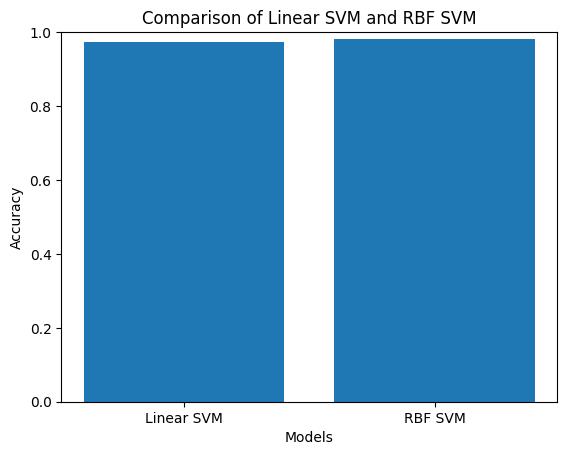

In [24]:
#compare linear and rbf svm
print("Linear SVM Accuracy:",accuracy_linear)
print("RBF SVM Accuracy:",accuracy_rbf)
if accuracy_linear>accuracy_rbf:
    print("Linear SVM performs better")
elif accuracy_rbf>accuracy_linear:
    print("RBF SVM perfrom better")
else:
  print("Both models have equal accuracy.")

#display comparison using a bar graph
models=['Linear SVM','RBF SVM']
accuracies=[accuracy_linear,accuracy_rbf]
plt.bar(models,accuracies)
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Comparison of Linear SVM and RBF SVM')
plt.ylim(0,1)
plt.show()

